# Question 1 - Linear Models and Maximum Likelihood

## Setup

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import numpy as np                 # math and arrays
import pandas as pd                # reading the CSV
import matplotlib.pyplot as plt    # plots

In [3]:
HW_DIR = "/content/drive/MyDrive/Computational Models - HW2"   # assignment folder in Drive
DATA_PATH = f"{HW_DIR}/data/HW2_q1_data.csv"                   # Q1 data file

df = pd.read_csv(DATA_PATH)        # load the table (columns: x1, y1)
x = df["x1"].to_numpy()            # stimulus
y = df["y1"].to_numpy()            # firing rate
N = len(y)                         # number of samples

print("N =", N)
df.head()

N = 50


,x1,y1
0,0.000000,10.993428
1,0.204082,10.335716
2,0.408163,12.519867
3,0.612245,14.882794
4,0.816327,11.980673


In [4]:
X = np.column_stack([np.ones(N), x])   # N x 2; the column of ones carries the intercept theta0
X[:3]

array([[1.        , 0.        ],
       [1.        , 0.20408163],
       [1.        , 0.40816327]])

## Task a

In [5]:
# theta = (X^T X)^-1 X^T y   ->  solved as a linear system (more stable than inverting)
theta_ols = np.linalg.solve(X.T @ X, X.T @ y)
theta0, theta1 = theta_ols

print(f"theta0 (intercept) = {theta0:.4f}")
print(f"theta1 (slope)     = {theta1:.4f}")

theta0 (intercept) = 10.1289
theta1 (slope)     = 2.8840


The least-squares solution is given by the normal equations, with design matrix $X = [\mathbf{1}, x]$:

$$\theta = (X^\top X)^{-1} X^\top y$$

(equivalently $\theta_1 = \mathrm{cov}(x,y)/\mathrm{var}(x)$ and $\theta_0 = \bar{y} - \theta_1 \bar{x}$).

**Result:** intercept $\theta_0 = 10.1289$, slope $\theta_1 = 2.8840$.

## Task b

In [6]:
learning_rate = 0.01      # step size (eta)
n_epochs = 10_000         # number of update steps

theta = np.zeros(2)                        # start from [0, 0]
losses = []                                # MSE after every epoch

for epoch in range(n_epochs):
    residuals = X @ theta - y              # prediction errors
    grad = (2 / N) * X.T @ residuals       # gradient of the MSE
    theta = theta - learning_rate * grad   # update step
    losses.append(np.mean((X @ theta - y) ** 2))

theta_gd = theta
print(f"learning rate = {learning_rate}, epochs = {n_epochs}")
print(f"GD:         theta0 = {theta_gd[0]:.4f}, theta1 = {theta_gd[1]:.4f}")
print(f"Analytical: theta0 = {theta_ols[0]:.4f}, theta1 = {theta_ols[1]:.4f}")
print(f"max |difference| = {np.max(np.abs(theta_gd - theta_ols)):.2e}")

learning rate = 0.01, epochs = 10000
GD:         theta0 = 10.1289, theta1 = 2.8840
Analytical: theta0 = 10.1289, theta1 = 2.8840
max |difference| = 1.58e-13


Batch gradient descent on the MSE:

$$\theta \leftarrow \theta - \eta \cdot \frac{2}{N} X^\top (X\theta - y)$$

**Chosen hyperparameters:** learning rate $\eta = 0.01$, 10,000 epochs, starting from $\theta = [0, 0]$. Larger learning rates (e.g. 0.05) caused divergence, so 0.01 was chosen; 10,000 epochs were enough for full convergence.

**Comparison:** gradient descent gives $\theta_0 = 10.1289$, $\theta_1 = 2.8840$, identical to the analytical solution (difference $\approx 10^{-13}$), as expected since the MSE has a single global minimum.

## Task c

In [7]:
y_hat = X @ theta_ols                      # model predictions

mse = np.mean((y - y_hat) ** 2)            # mean squared error
ss_res = np.sum((y - y_hat) ** 2)          # unexplained variance
ss_tot = np.sum((y - np.mean(y)) ** 2)     # total variance
r2 = 1 - ss_res / ss_tot                   # explained variance

print(f"MSE = {mse:.4f}")
print(f"R^2 = {r2:.4f}")

MSE = 3.3006
R^2 = 0.9563


$$\text{MSE} = \frac{1}{N}\sum_{i=1}^{N}(y_i - \hat{y}_i)^2, \qquad R^2 = 1 - \frac{\sum_i (y_i - \hat{y}_i)^2}{\sum_i (y_i - \bar{y})^2}$$

**Result:** $\text{MSE} = 3.3006$, $R^2 = 0.9563$. The stimulus explains about 95.6% of the variance in the firing rate.

## Task d

In [8]:
# LL = -N/2 * ln(2*pi*sigma^2) - SSE / (2*sigma^2)
sigma2 = mse
sse = np.sum((y - y_hat) ** 2)
ll = -N / 2 * np.log(2 * np.pi * sigma2) - sse / (2 * sigma2)

print(f"sigma^2 = MSE = {sigma2:.4f}")
print(f"SSE = {sse:.4f}")
print(f"LL = -{N}/2 * ln(2*pi*{sigma2:.4f}) - {sse:.4f}/(2*{sigma2:.4f})")
print(f"   = {-N / 2 * np.log(2 * np.pi * sigma2):.4f} - {sse / (2 * sigma2):.4f}")
print(f"   = {ll:.4f}")

sigma^2 = MSE = 3.3006
SSE = 165.0284
LL = -50/2 * ln(2*pi*3.3006) - 165.0284/(2*3.3006)
   = -75.7993 - 25.0000
   = -100.7993


Each observation is $y_i \sim \mathcal{N}(\hat{y}_i, \sigma^2)$, independently, so the log-likelihood is:

$$\text{LL} = \sum_{i=1}^{N} \ln\!\left[\frac{1}{\sqrt{2\pi\sigma^2}} \exp\!\left(-\frac{(y_i-\hat{y}_i)^2}{2\sigma^2}\right)\right] = -\frac{N}{2}\ln(2\pi\sigma^2) - \frac{\text{SSE}}{2\sigma^2}$$

**Calculation** with $\sigma^2 = \text{MSE} = 3.3006$, $N = 50$, $\text{SSE} = 165.0284$:

$$\text{LL} = -\frac{50}{2}\ln(2\pi \cdot 3.3006) - \frac{165.0284}{2 \cdot 3.3006} = -75.7993 - 25.0000 = -100.7993$$

Since only the SSE term depends on $\theta$, maximizing the likelihood is equivalent to minimizing the squared error.

## Task e

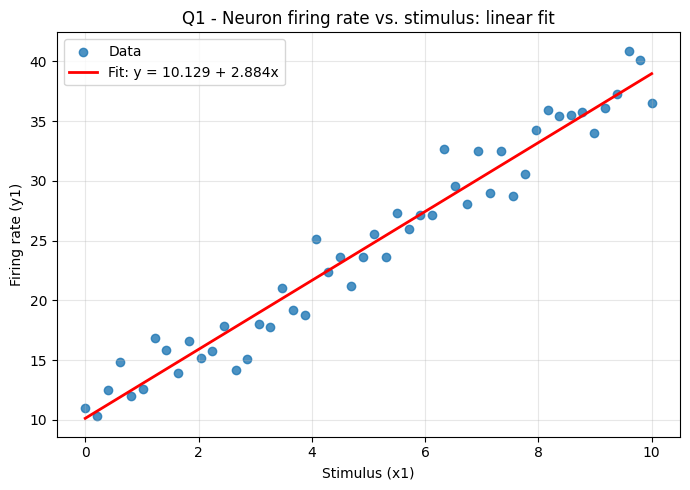

In [9]:
x_line = np.linspace(x.min(), x.max(), 200)        # smooth x values for the line
y_line = theta0 + theta1 * x_line                  # fitted line

plt.figure(figsize=(7, 5))
plt.scatter(x, y, alpha=0.8, label="Data")
plt.plot(x_line, y_line, color="red", linewidth=2,
         label=f"Fit: y = {theta0:.3f} + {theta1:.3f}x")
plt.title("Q1 - Neuron firing rate vs. stimulus: linear fit")
plt.xlabel("Stimulus (x1)")
plt.ylabel("Firing rate (y1)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{HW_DIR}/q1_linear_fit.png", dpi=150)  # save into the assignment folder
plt.show()

Data points (blue) and the fitted line $\hat{y} = 10.129 + 2.884x$ (red).